In [9]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy import ndimage

In [10]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# 1. Подбор параметров алгоритма разрастания регионов так, чтобы был выделен весь участок газона

In [11]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(mask)
    if abs(av_val - img[point]) <= T:
        return True
    return False

def region_growing(image, seed_point, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image.shape, np.uint8)
        for i in range(r, image.shape[0] - r):
            for j in range(r, image.shape[1] - r):
                if mask[i, j] == 0 and mask[i - r:i + r + 1, j - r:j + r + 1].sum() > 0:
                    if homo_fun(image, mask, (i, j), T):
                        local_mask[i, j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
    return mask * 255

In [12]:
seed_point = (250, 250)
r = 1
T = 28
mask = region_growing(image_gray, seed_point, homo_average, r, T)
mask_avg = mask

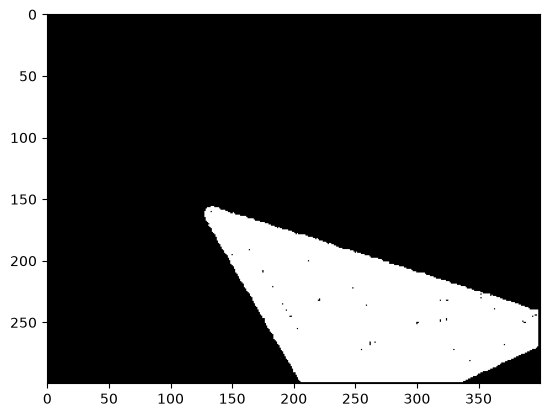

In [13]:
plt.imshow(mask, cmap="gray");

# 2. Реализация вычисления критерия однородности, отличного от представленного. Сравнение результатов

In [14]:
def homo_local(img, mask, point, T):
    i, j = point
    av_val = img[mask > 0].sum() / np.count_nonzero(mask)
    local_val = img[max(i - 2, 0):i + 3, max(j - 2, 0):j + 3].mean()
    if abs(av_val - local_val) <= T:
        return True
    return False

In [15]:
mask = region_growing(image_gray, seed_point, homo_local, 1, 20)
mask_local = mask

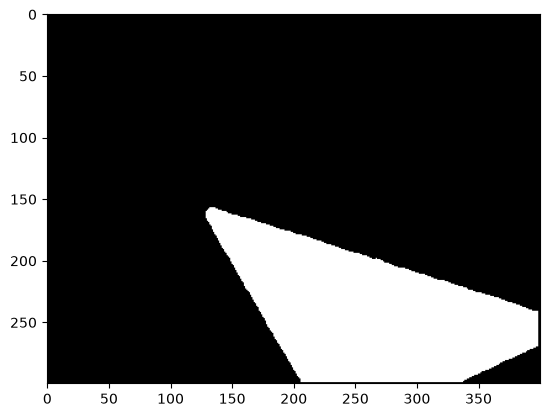

In [17]:
plt.imshow(mask_local, cmap="gray");

Сравнение результатов

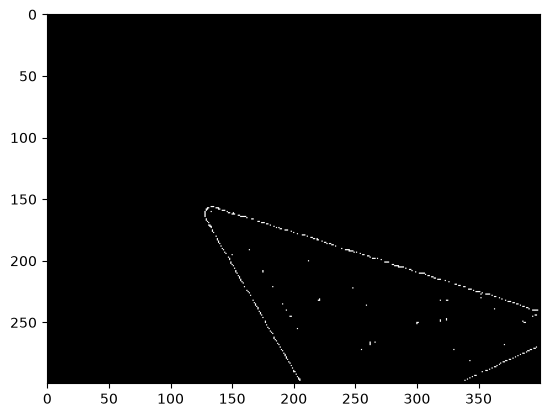

In [31]:
difference_mask = cv2.absdiff(mask_avg, mask_local)
plt.imshow(difference_mask, cmap="gray");

Новый критерий homo_local сравнивает со средним по области среднюю яркость окрестности 5×5 вокруг кандидата. Усреднение 25 пикселей сильно гасит шум.

# 3. Применение алгоритма сегментации watershed+distance transform для задачи подсчета пальмовых деревьев

In [33]:
image = cv2.imread('palm_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

Бинаризация

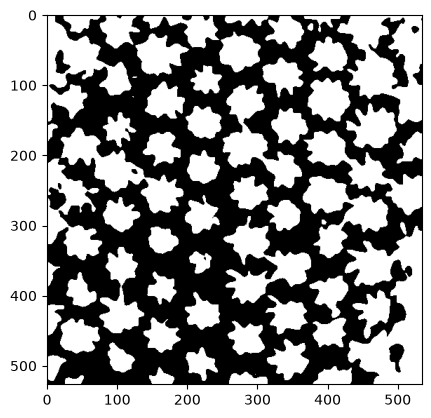

In [34]:
blurred = cv2.GaussianBlur(image_gray, (21, 21), 0)
ret, thresh = cv2.threshold(blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray");

Distance transform

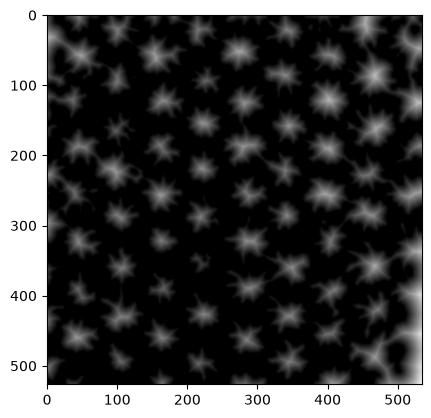

In [35]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5)
plt.imshow(dist, cmap="gray");

Ядра пальм

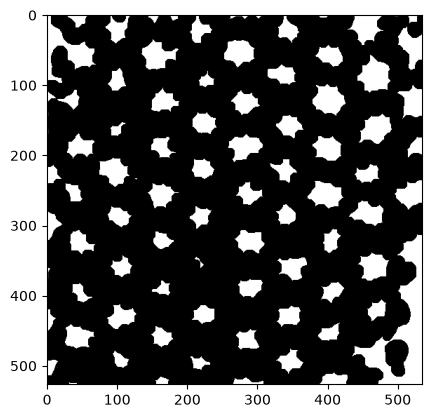

In [36]:
ret, sure_fg = cv2.threshold(dist, 0.2 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)
plt.imshow(sure_fg, cmap="gray");

Маркеры и watershed

Количество пальм: 85


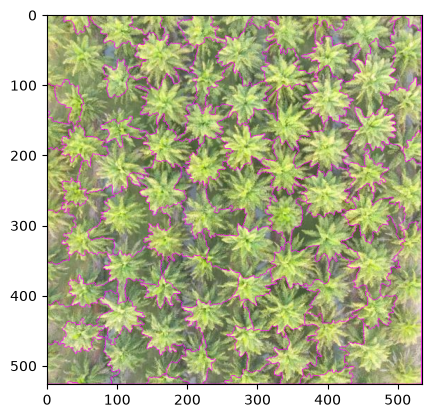

In [37]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = cv2.watershed(image, markers)

num = len(np.unique(markers[markers > 0]))
print("Количество пальм:", num)
result = image.copy()
result[markers == -1] = (255, 0, 255)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB));